# The training loop, made to tell the truth

**ERA V5 · Session 10.** Session 9 ended with one number, the loss. This notebook follows that number
backwards through a real 30M-parameter GPT running on a Colab T4, and checks every claim
instead of trusting it.

| # | The assignment asks | Where |
|---|---|---|
| 1 | Print every tensor shape in the step, one line per dimension | §1 |
| 2 | Verify one gradient by hand: nudge a weight, compare with `backward()` | §2 |
| 3 | Break gradient accumulation on purpose, plot both curves | §3 |
| 4 | Log the grad norm every step, find a step where it moved before the loss | §4 |
| 5 | Compute my own MFU, honestly, and explain the distance to 40% | §5 |
| 6 | Write 0.1 in fp32, bf16 and fp8 E4M3 by hand, pick a training format | §6 |

**Setup.** nanoGPT-style decoder: 6 layers, 6 heads, C=384, context 256, GPT-2 tokenizer (V padded to 50,304),
tied embeddings. Data is **TinyStories**: 27.6k short stories, so documents really do have different lengths,
which §3 needs. Everything runs top to bottom in about 10 minutes on a free T4.

In [1]:
!pip -q install tiktoken
import copy, json, math, os, struct, time, urllib.request
from fractions import Fraction
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, tiktoken
import matplotlib.pyplot as plt
from IPython.display import SVG, display

FIG = 'https://raw.githubusercontent.com/revantg/training-loop-truth/main/figures/'
def figure(name):
    display(SVG(urllib.request.urlopen(FIG + name).read()))

INK, ROSE, TEAL, AMBER, SLATE, SKY = '#4F46E5', '#E11D48', '#0D9488', '#F59E0B', '#64748B', '#0EA5E9'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'axes.titlelocation': 'left', 'legend.frameon': False})
print(torch.__version__, '|', torch.cuda.get_device_name() if torch.cuda.is_available() else 'no CUDA')

2.11.0+cu130 | Tesla T4


The model and data, kept in one cell so every section below uses exactly the same thing.
`rec(...)` does nothing unless `SHAPES` is a list, so the shape printout in §1 comes from the real forward
pass rather than a hand-written copy of it.

In [2]:
dev = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
if dev == 'cuda' and torch.cuda.is_bf16_supported(including_emulation=False):
    AMP = torch.bfloat16
elif dev == 'cuda':
    AMP = torch.float16          # T4 (Turing) has no bf16 tensor cores -> fp16 + loss scaling
else:
    AMP = None

URL = 'https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStoriesV2-GPT4-valid.txt'
if not os.path.exists('tinystories.txt'):
    urllib.request.urlretrieve(URL, 'tinystories.txt')
enc = tiktoken.get_encoding('gpt2')
EOS = enc.eot_token
stories = [s.strip() for s in open('tinystories.txt', encoding='utf-8').read().split('<|endoftext|>') if s.strip()]
docs = [d + [EOS] for d in enc.encode_ordinary_batch(stories)]          # one list of ids per story
n_split = int(0.95 * len(docs))
train_docs, val_docs = docs[:n_split], docs[n_split:]
train_data = torch.tensor([t for d in train_docs for t in d], dtype=torch.long).to(dev)   # packed stream
val_data = torch.tensor([t for d in val_docs for t in d], dtype=torch.long).to(dev)


class Cfg:
    vocab = 50304   # 50257 rounded up to a multiple of 64 for tensor-core friendly matmuls
    block = 256
    n_layer = 6
    n_head = 6
    n_embd = 384


SHAPES = None   # set to a list to record (name, shape, meaning) during one forward


def rec(name, t, meaning):
    if SHAPES is not None:
        SHAPES.append((name, tuple(t.shape), meaning))
    return t


class Block(nn.Module):
    def __init__(s, c):
        super().__init__(); s.c = c
        s.ln1, s.ln2 = nn.LayerNorm(c.n_embd), nn.LayerNorm(c.n_embd)
        s.c_attn, s.attn_proj = nn.Linear(c.n_embd, 3 * c.n_embd), nn.Linear(c.n_embd, c.n_embd)
        s.fc, s.mlp_proj = nn.Linear(c.n_embd, 4 * c.n_embd), nn.Linear(4 * c.n_embd, c.n_embd)

    def forward(s, x, first=False):
        r = rec if first else (lambda n, t, m: t)
        B, T, C = x.shape; nh = s.c.n_head; hd = C // nh
        qkv = r('qkv = c_attn(ln1(x))', s.c_attn(s.ln1(x)), 'B, T, 3C: q, k and v for every position, side by side')
        q, k, v = (t.view(B, T, nh, hd).transpose(1, 2) for t in qkv.split(C, 2))
        r('q (k, v identical)', q, 'B, heads, T, head_dim: each head works on its own 64-wide slice of C')
        r('scores q·kᵀ/√d (virtual)', torch.empty(B, nh, T, T, device='meta'), 'B, heads, T_query, T_key: SDPA fuses this, never stored')
        y = r('softmax(scores)·v', F.scaled_dot_product_attention(q, k, v, is_causal=True), 'B, heads, T, head_dim: weighted mix of earlier v')
        y = r('heads merged', y.transpose(1, 2).reshape(B, T, C), 'B, T, C: heads concatenated back into the channel axis')
        x = r('x + attn_proj(y)', x + s.attn_proj(y), 'B, T, C: residual stream after attention')
        h = r('fc(ln2(x))', s.fc(s.ln2(x)), 'B, T, 4C: the MLP widens every position 4x')
        return r('x + mlp_proj(gelu(h))', x + s.mlp_proj(F.gelu(h)), 'B, T, C: residual stream leaving the block')


class GPT(nn.Module):
    def __init__(s, c):
        super().__init__(); s.c = c
        s.wte, s.wpe = nn.Embedding(c.vocab, c.n_embd), nn.Embedding(c.block, c.n_embd)
        s.blocks = nn.ModuleList(Block(c) for _ in range(c.n_layer))
        s.ln_f = nn.LayerNorm(c.n_embd)
        s.head = nn.Linear(c.n_embd, c.vocab, bias=False)
        s.head.weight = s.wte.weight    # tied: one matrix both reads and writes tokens
        for name, p in s.named_parameters():
            if p.dim() == 2:
                std = 0.02 / math.sqrt(2 * c.n_layer) if name.endswith('proj.weight') else 0.02
                nn.init.normal_(p, 0.0, std)
            elif name.endswith('bias'):
                nn.init.zeros_(p)

    def forward(s, idx):
        B, T = rec('idx', idx, 'B, T: token ids, B sequences of T positions').shape
        tok = rec('wte(idx)', s.wte(idx), 'B, T, C: one C-wide vector per token')
        pos = rec('wpe(arange(T))', s.wpe(torch.arange(T, device=idx.device)), 'T, C: one vector per position, broadcast over B')
        x = rec('x = tok + pos', tok + pos, 'B, T, C: the residual stream')
        for i, b in enumerate(s.blocks):
            x = b(x, first=(i == 0))
        rec('after all 6 blocks', x, 'B, T, C: blocks 1-5 repeat block 0 exactly')
        x = rec('ln_f(x)', s.ln_f(x), 'B, T, C: normalised before the head')
        return rec('logits = head(x)', s.head(x), 'B, T, V: a score for every vocabulary entry at every position')


def n_params(m, exclude_pos=False):
    n = sum(p.numel() for p in m.parameters())
    return n - m.wpe.weight.numel() if exclude_pos else n


def get_batch(split, B, T, gen=None):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - T - 1, (B,), generator=gen).to(d.device)
    off = torch.arange(T, device=d.device)
    return d[ix[:, None] + off], d[ix[:, None] + off + 1]     # target = the next token


def autocast():
    return torch.autocast(dev, dtype=AMP) if AMP else torch.autocast(dev, enabled=False)


def make_opt(m, lr):
    decay = [p for p in m.parameters() if p.dim() >= 2]
    rest = [p for p in m.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{'params': decay, 'weight_decay': 0.1}, {'params': rest, 'weight_decay': 0.0}],
                             lr=lr, betas=(0.9, 0.95), fused=(dev == 'cuda'))


def lr_at(step, peak, warmup, total, floor=0.1):
    if step < warmup:
        return peak * (step + 1) / warmup
    p = (step - warmup) / max(1, total - warmup)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p)))


def sync():
    if dev == 'cuda': torch.cuda.synchronize()


V = Cfg.vocab
lens = np.array([len(d) for d in docs])
print(f'device {dev}, autocast {AMP} | {len(docs):,} stories, {len(train_data):,} train / {len(val_data):,} val tokens')
print(f'story length in tokens: median {np.median(lens):.0f}, 10th pct {np.percentile(lens, 10):.0f}, 90th pct {np.percentile(lens, 90):.0f}')

device cuda, autocast torch.float16 | 27,630 stories, 5,196,293 train / 272,731 val tokens
story length in tokens: median 177, 10th pct 137, 90th pct 267


## 1 · Every tensor shape in one step

One step is five lines: forward, loss, backward, update, wipe. The figure is the map, the table below is what the
real step produced. **B = 16 sequences · T = 256 positions · C = 384 channels · V = 50,304 vocabulary entries ·
6 heads × 64 dims.**

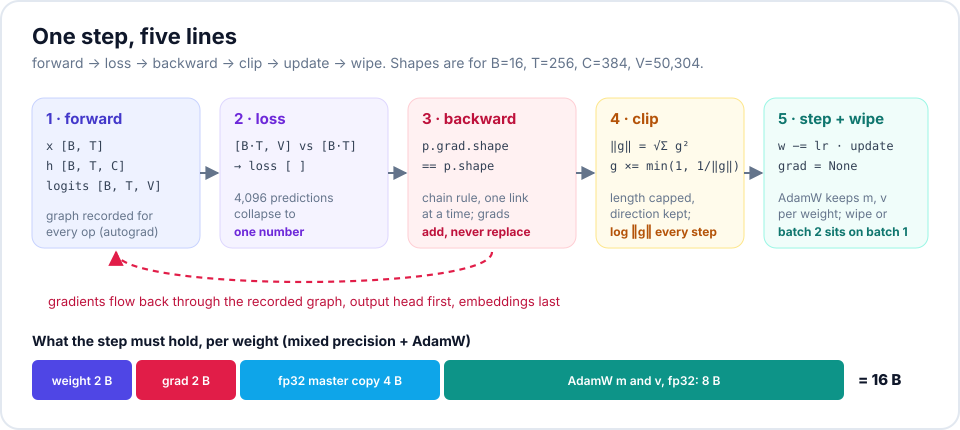

In [3]:
figure('01-one-step.svg')

In [4]:
torch.manual_seed(0)
model = GPT(Cfg()).to(dev)
opt = make_opt(model, 1e-3)
x, y = get_batch('train', 16, 256, torch.Generator().manual_seed(0))

SHAPES = []
logits = model(x)                                              # 1 forward
fwd, SHAPES = SHAPES, None
logits.retain_grad()
loss = F.cross_entropy(logits.view(-1, V), y.view(-1))         # 2 loss
loss.backward()                                                # 3 backward
gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # 4 clip, and the norm to log
opt.step()                                                     # 5 update ...
wte = model.wte.weight
rows = fwd + [
    ('y (targets)', tuple(y.shape), 'B, T: x shifted left by one, the token each position must predict'),
    ('logits.view(-1, V)', (logits.shape[0] * logits.shape[1], V), 'B·T, V: every position becomes one 50,304-way classification'),
    ('loss', tuple(loss.shape), '(): one scalar, the mean over all 4,096 predictions'),
    ('logits.grad', tuple(logits.grad.shape), 'B, T, V: (softmax − one_hot) / (B·T), the first thing backward() produces'),
    ('wte.weight.grad', tuple(wte.grad.shape), 'V, C: always the weight\'s own shape; tied, so it sums the head and embedding paths'),
    ('blocks[0].c_attn.weight.grad', tuple(model.blocks[0].c_attn.weight.grad.shape), '3C, C: nn.Linear stores (out_features, in_features)'),
    ('blocks[0].fc.weight.grad', tuple(model.blocks[0].fc.weight.grad.shape), '4C, C: the MLP up-projection'),
    ('ln_f.weight.grad', tuple(model.ln_f.weight.grad.shape), 'C: one gain per channel'),
    ('grad norm', tuple(gn.shape), '(): one number summarising all 30M gradients'),
    ('AdamW exp_avg (wte)', tuple(opt.state[wte]['exp_avg'].shape), 'V, C: running mean of the gradient, fp32, per weight'),
    ('AdamW exp_avg_sq (wte)', tuple(opt.state[wte]['exp_avg_sq'].shape), 'V, C: running mean of the squared gradient'),
]
opt.zero_grad(set_to_none=True)                                # ... and wipe
pd.set_option('display.max_colwidth', 120)
display(pd.DataFrame(rows, columns=['tensor', 'shape', 'what each dimension means']))

,tensor,shape,what each dimension means
0,idx,"(16, 256)","B, T: token ids, B sequences of T positions"
1,wte(idx),"(16, 256, 384)","B, T, C: one C-wide vector per token"
2,wpe(arange(T)),"(256, 384)","T, C: one vector per position, broadcast over B"
3,x = tok + pos,"(16, 256, 384)","B, T, C: the residual stream"
4,qkv = c_attn(ln1(x)),"(16, 256, 1152)","B, T, 3C: q, k and v for every position, side by side"
5,"q (k, v identical)","(16, 6, 256, 64)","B, heads, T, head_dim: each head works on its own 64-wide slice of C"
6,scores q·kᵀ/√d (virtual),"(16, 6, 256, 256)","B, heads, T_query, T_key: SDPA fuses this, never stored"
7,softmax(scores)·v,"(16, 6, 256, 64)","B, heads, T, head_dim: weighted mix of earlier v"
8,heads merged,"(16, 256, 384)","B, T, C: heads concatenated back into the channel axis"
9,x + attn_proj(y),"(16, 256, 384)","B, T, C: residual stream after attention"


Two checks on the shapes, because a right shape can still hold wrong numbers:

* `logits.grad` should be `(softmax − one_hot)/(B·T)`, so every row sums to zero and the target entry is `(p − 1)/(B·T)`.
* Every parameter's gradient must have exactly the parameter's shape, and nothing may be left with `grad=None` after backward.

In [5]:
g = logits.grad.float()
p = logits.detach().float().softmax(-1)
expected = (p - F.one_hot(y, V).float()) / y.numel()
print(f'max |row sum of logits.grad|           {g.sum(-1).abs().max().item():.2e}   (should be ~0)')
print(f'max |logits.grad − (softmax−onehot)/BT| {(g - expected).abs().max().item():.2e}   (should be ~0)')
counts = {'embedding (wte, tied with head)': wte.numel(), 'positions (wpe)': model.wpe.weight.numel(),
          'one transformer block': sum(p.numel() for p in model.blocks[0].parameters()), 'final layernorm': 2 * Cfg.n_embd}
print(pd.Series(counts).map('{:,}'.format).to_string())
print(f'total {n_params(model):,} parameters; the head re-uses wte so it adds 0 (untied it would add {wte.numel():,})')
del logits, g, p, expected

max |row sum of logits.grad|           2.11e-10   (should be ~0)
max |logits.grad − (softmax−onehot)/BT| 2.49e-14   (should be ~0)
embedding (wte, tied with head)    19,316,736
positions (wpe)                        98,304
one transformer block               1,774,464
final layernorm                           768
total 30,062,592 parameters; the head re-uses wte so it adds 0 (untied it would add 19,316,736)


## 2 · One gradient, checked by hand

`backward()` multiplies local slopes from the loss back to each weight. The nudge needs no calculus: move one
weight by ±ε and measure the loss. Central difference error shrinks like ε², so in **float64** the two should
agree to many digits. First the lecture's toy chain, then the real model.

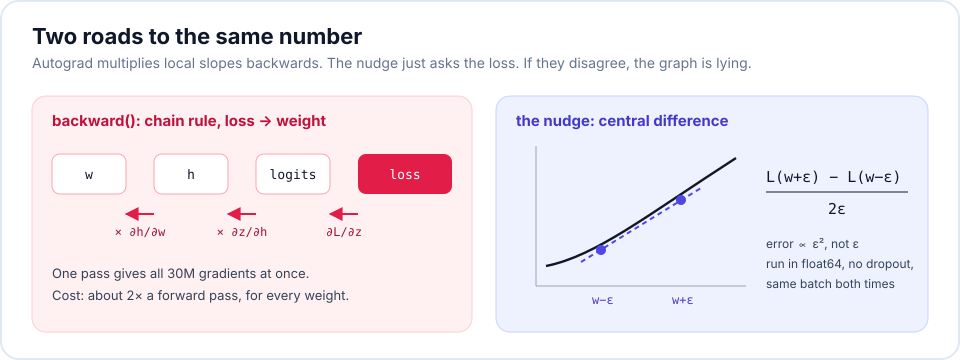

In [6]:
figure('02-nudge.svg')

In [7]:
w1, w2 = torch.tensor(3.0, dtype=torch.float64, requires_grad=True), torch.tensor(4.0, dtype=torch.float64, requires_grad=True)
toy = lambda a: ((w2 * (a * 2.0)) - 20.0) ** 2           # x = 2, t = 20, loss = (w2·w1·x − t)²
toy(w1).backward()
eps = 1e-6
print(f'lecture chain:  backward() {w1.grad.item():.8f}   nudge {((toy(w1 + eps) - toy(w1 - eps)) / (2 * eps)).item():.8f}')

lecture chain:  backward() 64.00000000   nudge 64.00000001


In [8]:
torch.manual_seed(0)
m64 = GPT(Cfg()).to(dev).double()                          # float64 copy: roundoff ~1e-16, no autocast
xb, yb = get_batch('train', 4, 64, torch.Generator().manual_seed(1))
def loss64(): return F.cross_entropy(m64(xb).view(-1, V), yb.view(-1))
loss64().backward()

tok = int(xb[0, 5])                                         # a token that appears in the batch
targets = [('blocks[0].fc.weight', m64.blocks[0].fc.weight, None),
           ('blocks[5].attn_proj.weight', m64.blocks[5].attn_proj.weight, None),
           ('ln_f.weight', m64.ln_f.weight, None),
           ('wpe.weight (position 3)', m64.wpe.weight, (3, 7)),
           (f'wte.weight (token {enc.decode([tok])!r}, tied)', m64.wte.weight, (tok, 11))]
out = []
with torch.no_grad():
    for name, P, idx in targets:
        idx = idx or np.unravel_index(int(P.grad.abs().argmax()), P.shape)  # the weight that matters most
        ana, w0, h = P.grad[idx].item(), P[idx].item(), 1e-5
        P[idx] = w0 + h; lp = loss64().item()
        P[idx] = w0 - h; lm = loss64().item()
        P[idx] = w0
        num = (lp - lm) / (2 * h)
        out.append((name, tuple(int(i) for i in np.atleast_1d(idx)), ana, num, abs(num - ana) / abs(ana)))
display(pd.DataFrame(out, columns=['weight', 'index', 'backward()', 'nudge (L₊−L₋)/2ε', 'relative error'])
        .style.format({'backward()': '{:.10e}', 'nudge (L₊−L₋)/2ε': '{:.10e}', 'relative error': '{:.1e}'}))

,weight,index,backward(),nudge (L₊−L₋)/2ε,relative error
0,blocks[0].fc.weight,"(399, 315)",-1.3185790894e-02,-1.3185790948e-02,4.1e-09
1,blocks[5].attn_proj.weight,"(146, 126)",5.3563493161e-02,5.3563493196e-02,6.6e-10
2,ln_f.weight,"(229,)",-6.8257657423e-03,-6.8257657304e-03,1.7e-09
3,wpe.weight (position 3),"(3, 7)",1.1577505115e-02,1.1577505088e-02,2.4e-09
4,"wte.weight (token ' She', tied)","(1375, 11)",2.5933229878e-03,2.5933230674e-03,3.1e-08


They agree to **8–10 significant digits** (relative error 7×10⁻¹⁰ to 3×10⁻⁸) on five weights from five different kinds of
layer. The weakest agreement is the tied `wte` entry, and that is the interesting one: its gradient is the *sum* of two paths,
the embedding lookup at the bottom and the output head at the top. The nudge sees both paths at once because it only asks the
loss, so agreement there also confirms that autograd adds the two contributions correctly.

**Where it stops agreeing.** Repeat the nudge in the precisions we actually train in. Two errors pull in opposite directions:
truncation (∝ ε², hurts at large ε) and roundoff (∝ machine-ε·|L|/ε, hurts at small ε). A loss of ~11 stored in fp32 is only
known to about ±10⁻⁶, so a nudge of 10⁻⁵ moves it by less than its own rounding noise.

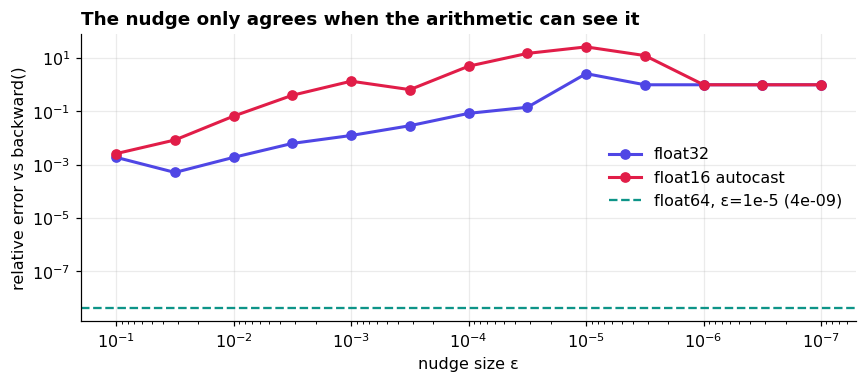

           float32: best relative error 5.2e-04 at ε = 3e-02
  float16 autocast: best relative error 2.6e-03 at ε = 1e-01


In [9]:
P64 = m64.blocks[0].fc.weight
idx = np.unravel_index(int(P64.grad.abs().argmax()), P64.shape)
ana = P64.grad[idx].item()
m32 = copy.deepcopy(m64).float()
P32 = m32.blocks[0].fc.weight
eps_grid = np.logspace(-1, -7, 13)
curves = {}
for label, ctx in (('float32', torch.autocast(dev, enabled=False)), (f'{str(AMP).split(".")[-1]} autocast' if AMP else 'float32 (no AMP)', autocast())):
    errs = []
    with torch.no_grad():
        for h in eps_grid:
            w0 = P32[idx].item()
            P32[idx] = w0 + h
            with ctx: lp = F.cross_entropy(m32(xb).float().view(-1, V), yb.view(-1)).item()
            P32[idx] = w0 - h
            with ctx: lm = F.cross_entropy(m32(xb).float().view(-1, V), yb.view(-1)).item()
            P32[idx] = w0
            errs.append(abs((lp - lm) / (2 * h) - ana) / abs(ana))
    curves[label] = np.array(errs)
fig, ax = plt.subplots(figsize=(8, 3.6))
for (label, e), c in zip(curves.items(), (INK, ROSE)):
    ax.loglog(eps_grid, np.maximum(e, 1e-12), 'o-', color=c, label=label, lw=2)
ax.axhline(out[0][-1], color=TEAL, ls='--', lw=1.5, label=f'float64, ε=1e-5 ({out[0][-1]:.0e})')
ax.set(xlabel='nudge size ε', ylabel='relative error vs backward()', title='The nudge only agrees when the arithmetic can see it')
ax.invert_xaxis(); ax.legend(); plt.tight_layout(); plt.show()
for label, e in curves.items():
    print(f'{label:>18}: best relative error {e.min():.1e} at ε = {eps_grid[e.argmin()]:.0e}')

And the line from the lecture that surprises people: **gradients add, they do not replace.** Calling `backward()` twice
without `zero_grad()` gives exactly twice the gradient, and nothing raises an error.

In [10]:
m64.zero_grad(); loss64().backward(); g1 = P64.grad[idx].item()
loss64().backward(); g2 = P64.grad[idx].item()
print(f'after one backward {g1:.10f} | after a second, no wipe {g2:.10f} | ratio {g2 / g1:.6f}')
del m64, m32

after one backward -0.0131857909 | after a second, no wipe -0.0263715818 | ratio 2.000000


## 3 · Breaking gradient accumulation on purpose

Each optimiser step here is built from **four micro-batches of different lengths**: 8 stories each, cut to
T = 16, 32, 128 and 256 tokens and right-padded, with padding masked out of the loss. Real tokens per
micro-batch differ by about 10×. Two ways to combine them:

* **correct:** `loss_i = sum of token losses_i / N_total`, so every token in the step gets the same weight;
* **broken (pre-2024 frameworks):** `loss_i = mean of token losses_i / 4`, the average of averages.

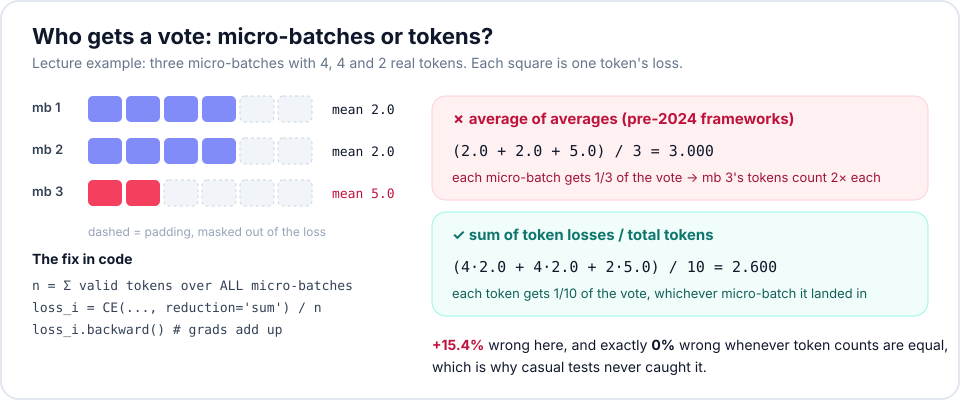

In [11]:
figure('03-accumulation.svg')

In [12]:
n_tok, means = np.array([4, 4, 2]), np.array([2.0, 2.0, 5.0])
right, wrong = (n_tok * means).sum() / n_tok.sum(), means.mean()
print(f'lecture example: correct {right:.4f}, average of averages {wrong:.4f}, {100 * (wrong / right - 1):.1f}% too high')

lecture example: correct 2.6000, average of averages 3.0000, 15.4% too high


In [13]:
MB_T, MB_B = (16, 32, 128, 256), 8

def doc_batch(pool, B, T, gen):
    """B stories, each starting at its first token, cut to T, right-padded; padded targets are -100."""
    x = torch.full((B, T), EOS, dtype=torch.long); y = torch.full((B, T), -100, dtype=torch.long)
    for r, i in enumerate(torch.randint(len(pool), (B,), generator=gen).tolist()):
        d = torch.tensor(pool[i][:T + 1]); n = len(d) - 1
        x[r, :n], y[r, :n] = d[:-1], d[1:]
    return x.to(dev), y.to(dev)

def step_batches(gen):
    return [doc_batch(train_docs, MB_B, T, gen) for T in MB_T]

def accumulate(m, mbs, mode, use_amp=True, scaler=None):
    """Run backward over every micro-batch; return (true per-token loss, average-of-averages)."""
    n_total = sum(int((y != -100).sum()) for _, y in mbs)
    tot, avgs = 0.0, []
    for x, y in mbs:
        with (autocast() if use_amp else torch.autocast(dev, enabled=False)):
            s = F.cross_entropy(m(x).float().view(-1, V), y.view(-1), ignore_index=-100, reduction='sum')
        n = int((y != -100).sum())
        part = s / n_total if mode == 'correct' else (s / n) / len(mbs)
        (scaler.scale(part) if scaler else part).backward()
        tot += s.item(); avgs.append(s.item() / n)
    return tot / n_total, float(np.mean(avgs))

# Ground truth: the four micro-batches padded to T=256 and run as ONE batch, per-token mean.
torch.manual_seed(0); base = GPT(Cfg()).to(dev)
mbs = step_batches(torch.Generator().manual_seed(3))
full_x = torch.cat([F.pad(x, (0, 256 - x.shape[1]), value=EOS) for x, _ in mbs])
full_y = torch.cat([F.pad(y, (0, 256 - y.shape[1]), value=-100) for _, y in mbs])
def flat_grad(m): return torch.cat([p.grad.flatten() for p in m.parameters()])
F.cross_entropy(base(full_x).view(-1, V), full_y.view(-1), ignore_index=-100).backward()
g_ref = flat_grad(base).clone()
res = []
for mode in ('correct', 'broken'):
    base.zero_grad(); accumulate(base, mbs, mode, use_amp=False)
    g = flat_grad(base)
    res.append((mode, ((g - g_ref).norm() / g_ref.norm()).item(), F.cosine_similarity(g, g_ref, 0).item(), (g.norm() / g_ref.norm()).item()))
print('valid tokens per micro-batch:', [int((y != -100).sum()) for _, y in mbs])
display(pd.DataFrame(res, columns=['accumulation', '‖g − g_full‖ / ‖g_full‖', 'cosine to full batch', '‖g‖ / ‖g_full‖'])
        .style.format(precision=6))
del base, g_ref

valid tokens per micro-batch: [128, 256, 1017, 1355]


,accumulation,‖g − g_full‖ / ‖g_full‖,cosine to full batch,‖g‖ / ‖g_full‖
0,correct,0.000001,1.000000,1.000000
1,broken,0.481721,0.917784,1.190513


Correct accumulation reproduces the one-big-batch gradient to float32 roundoff. The broken one points somewhere
else entirely. Now train both from the same initial weights on the same micro-batches in the same order,
and log both ways of reporting the loss.

In [14]:
def accum_run(mode, steps=800, peak=1e-3, warmup=50, seed=0):
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(42)
    m = GPT(Cfg()).to(dev); o = make_opt(m, peak); sc = torch.amp.GradScaler(enabled=(AMP == torch.float16))
    vgen = torch.Generator().manual_seed(7)
    val = [doc_batch(val_docs, 32, 256, vgen) for _ in range(4)]
    H = {'true': [], 'avg_avg': [], 'val_step': [], 'val_short': [], 'val_long': []}
    for step in range(steps):
        for pg in o.param_groups: pg['lr'] = lr_at(step, peak, warmup, steps)
        t, a = accumulate(m, step_batches(gen), mode, scaler=sc)
        sc.unscale_(o); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        sc.step(o); sc.update(); o.zero_grad(set_to_none=True)
        H['true'].append(t); H['avg_avg'].append(a)
        if step % 50 == 0 or step == steps - 1:
            m.eval(); s16 = n16 = sl = nl = 0.0
            with torch.no_grad(), autocast():
                for x, y in val:
                    l = F.cross_entropy(m(x).float().view(-1, V), y.view(-1), ignore_index=-100, reduction='none').view(y.shape)
                    ok = y != -100
                    s16 += l[:, :16][ok[:, :16]].sum().item(); n16 += ok[:, :16].sum().item()
                    sl += l[:, 16:][ok[:, 16:]].sum().item(); nl += ok[:, 16:].sum().item()
            m.train(); H['val_step'].append(step); H['val_short'].append(s16 / n16); H['val_long'].append(sl / nl)
    print(f'{mode:>8}: final train loss {np.mean(H["true"][-50:]):.4f}, val (pos<16) {H["val_short"][-1]:.4f}, val (pos≥16) {H["val_long"][-1]:.4f}')
    return {k: np.array(v) for k, v in H.items()}

t0 = time.time()
ACC = {mode: accum_run(mode) for mode in ('correct', 'broken')}
print(f'{time.time() - t0:.0f}s')

 correct: final train loss 2.5269, val (pos<16) 1.5134, val (pos≥16) 2.9709
  broken: final train loss 2.7524, val (pos<16) 1.5374, val (pos≥16) 3.2488
184s


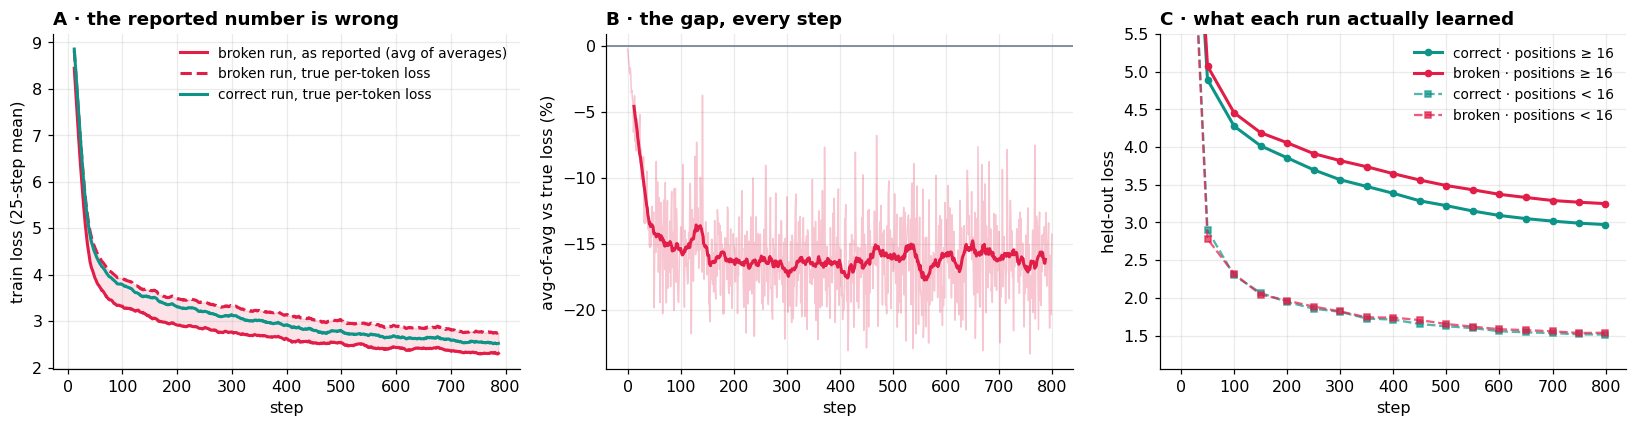

average-of-averages vs the true per-token loss: -16.2% over the last 100 steps (every step between -23.3% and -0.3%)
held-out, positions ≥16:  correct 2.9709  broken 3.2488  Δ +0.2779
held-out, positions <16:  correct 1.5134  broken 1.5374  Δ +0.0240


In [16]:
def smooth(a, k=25): return np.convolve(a, np.ones(k) / k, 'valid')
C, Bk = ACC['correct'], ACC['broken']
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
s = np.arange(len(smooth(C['true']))) + 12
ax[0].plot(s, smooth(Bk['avg_avg']), color=ROSE, lw=2, label='broken run, as reported (avg of averages)')
ax[0].plot(s, smooth(Bk['true']), color=ROSE, lw=2, ls='--', label='broken run, true per-token loss')
ax[0].plot(s, smooth(C['true']), color=TEAL, lw=2, label='correct run, true per-token loss')
ax[0].fill_between(s, smooth(Bk['true']), smooth(Bk['avg_avg']), color=ROSE, alpha=0.12)
ax[0].set(title='A · the reported number is wrong', xlabel='step', ylabel='train loss (25-step mean)')
ax[0].legend(fontsize=9)
gap = 100 * (Bk['avg_avg'] / Bk['true'] - 1)
ax[1].plot(gap, color=ROSE, alpha=0.25, lw=1); ax[1].plot(s, smooth(gap), color=ROSE, lw=2)
ax[1].axhline(0, color=SLATE, lw=1)
ax[1].set(title='B · the gap, every step', xlabel='step', ylabel='avg-of-avg vs true loss (%)')
vs = C['val_step']
ax[2].plot(vs, C['val_long'], 'o-', color=TEAL, lw=2, ms=4, label='correct · positions ≥ 16')
ax[2].plot(vs, Bk['val_long'], 'o-', color=ROSE, lw=2, ms=4, label='broken · positions ≥ 16')
ax[2].plot(vs, C['val_short'], 's--', color=TEAL, lw=1.5, ms=4, alpha=0.7, label='correct · positions < 16')
ax[2].plot(vs, Bk['val_short'], 's--', color=ROSE, lw=1.5, ms=4, alpha=0.7, label='broken · positions < 16')
ax[2].set(title='C · what each run actually learned', xlabel='step', ylabel='held-out loss', ylim=(None, 5.5))
ax[2].legend(fontsize=9)
plt.tight_layout(); plt.show()
last = slice(-100, None)
print(f'average-of-averages vs the true per-token loss: {gap[last].mean():+.1f}% over the last 100 steps (every step between {gap.min():+.1f}% and {gap.max():+.1f}%)')
print(f'held-out, positions ≥16:  correct {C["val_long"][-1]:.4f}  broken {Bk["val_long"][-1]:.4f}  Δ {Bk["val_long"][-1] - C["val_long"][-1]:+.4f}')
print(f'held-out, positions <16:  correct {C["val_short"][-1]:.4f}  broken {Bk["val_short"][-1]:.4f}  Δ {Bk["val_short"][-1] - C["val_short"][-1]:+.4f}')

**What happened.**

* **The gradient.** Correct accumulation matches the one-big-batch gradient to 7.7×10⁻⁷, which is float32 roundoff. The broken
  one is **48% off**, with cosine 0.92 and 1.19× the length. It points somewhere else.
* **The sign surprised me.** The lecture example came out 15.4% *too high*. Here the average of averages reads **16% too low**,
  so the broken run's dashboard (panel A, solid red) shows a *better* loss than the correct run while it is actually worse.
  The sign depends on which micro-batches are easy. The T=16 micro-batch only holds story openings ("Once upon a time, there
  was a little…"), which are very predictable, and the average of averages gives those 128 tokens the same vote as the 1,355
  tokens of the T=256 batch, about **5× too much weight per token**. Easy tokens get over-weighted, so the number looks good.
  Make the short batches the hard ones and the same bug overstates the loss instead. Either way the number is wrong, and you
  can't tell which way from the curve.
* **The damage is real.** Held-out loss at positions ≥ 16 ends at **3.249 against 2.971** (+0.28 nats, about where the correct run
  already was at step ~475 of 800). At positions < 16, the thing the broken run over-trained on, the two runs are level
  (1.537 vs 1.513). The usual effective-sample-size formula, (Σw)²/Σw², gives about 1,190 effective tokens per step out of
  2,756: the broken run spends more than half its data on gradient it mostly throws away.

**Takeaway:** normalise by the total number of real tokens in the whole step. Do it once, before the first `backward()`.

## 4 · The grad norm, every step

A normal run first: 2,000 steps of 16 × 256 tokens, AdamW at peak LR 1e-3 with warmup and cosine decay, clipping at 1.0,
and the grad norm (measured **before** clipping) logged at every step along with the loss, LR, fp16 loss scale and
step time.

In [17]:
def train_run(steps, peak_lr, warmup, B=16, T=256, clip=1.0, seed=0, log_every=250):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(1234)
    m = GPT(Cfg()).to(dev); o = make_opt(m, peak_lr); sc = torch.amp.GradScaler(enabled=(AMP == torch.float16))
    H = {k: [] for k in ('loss', 'gnorm', 'lr', 'scale', 'dt')}
    for step in range(steps):
        t0 = time.perf_counter()
        for pg in o.param_groups: pg['lr'] = lr_at(step, peak_lr, warmup, steps)
        x, y = get_batch('train', B, T, g)
        with autocast():
            loss = F.cross_entropy(m(x).float().view(-1, V), y.view(-1))
        sc.scale(loss).backward()
        sc.unscale_(o)
        gn = torch.nn.utils.clip_grad_norm_(m.parameters(), clip)
        sc.step(o); sc.update(); o.zero_grad(set_to_none=True)
        H['loss'].append(loss.item()); H['gnorm'].append(gn.item())      # .item() syncs, so dt is honest wall time
        H['lr'].append(o.param_groups[0]['lr']); H['scale'].append(sc.get_scale() if sc.is_enabled() else 1.0)
        H['dt'].append(time.perf_counter() - t0)
        if step % log_every == 0 or step == steps - 1:
            print(f'step {step:5d}  loss {H["loss"][-1]:.3f}  |g| {H["gnorm"][-1]:6.3f}  lr {H["lr"][-1]:.2e}  {H["dt"][-1] * 1e3:5.1f} ms')
    return m, {k: np.array(v) for k, v in H.items()}

MAIN_B, MAIN_T = 16, 256
main_model, MAIN = train_run(2000, 1e-3, 100, B=MAIN_B, T=MAIN_T)

step     0  loss 10.878  |g|  8.844  lr 1.00e-05  111.0 ms
step   250  loss 3.394  |g|  0.907  lr 9.86e-04   93.4 ms
step   500  loss 3.063  |g|  1.108  lr 9.05e-04   93.3 ms
step   750  loss 2.691  |g|  0.919  lr 7.64e-04   90.7 ms
step  1000  loss 2.466  |g|  0.929  lr 5.87e-04   90.8 ms
step  1250  loss 2.411  |g|  0.951  lr 4.04e-04   92.3 ms
step  1500  loss 2.429  |g|  0.971  lr 2.45e-04   92.5 ms
step  1750  loss 2.087  |g|  0.942  lr 1.38e-04   92.2 ms
step  1999  loss 2.323  |g|  0.988  lr 1.00e-04   92.8 ms


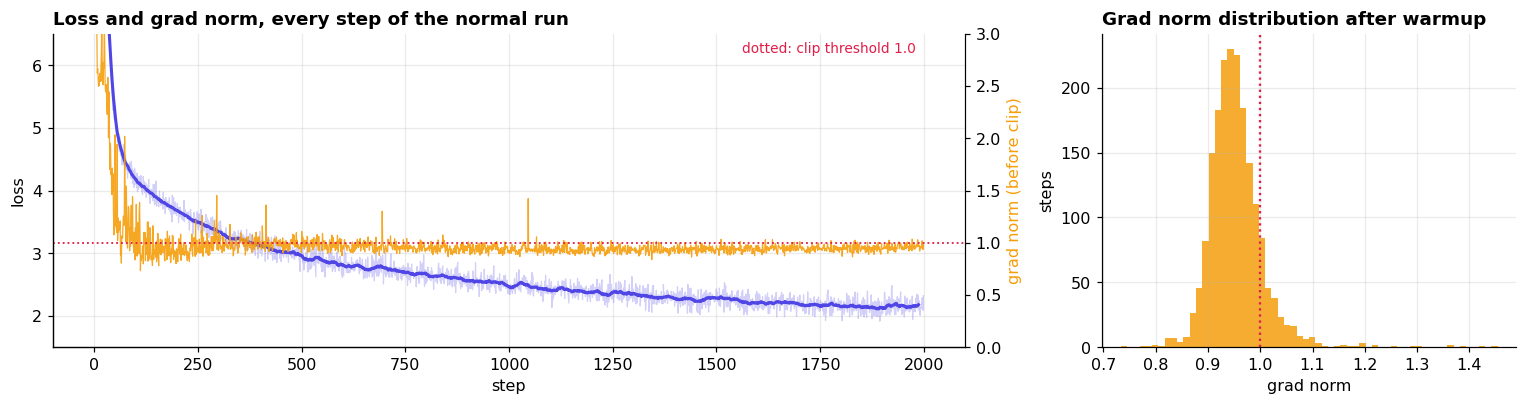

grad norm after warmup: median 0.948, p95 1.036, p99 1.114, max 1.454
clip at 1.0 was active on 13% of post-warmup steps


In [18]:
L, G = MAIN['loss'], MAIN['gnorm']
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].plot(L, color=INK, alpha=0.25, lw=0.8); ax[0].plot(np.arange(len(smooth(L))) + 12, smooth(L), color=INK, lw=2, label='loss')
ax[0].set(xlabel='step', ylabel='loss', title='Loss and grad norm, every step of the normal run', ylim=(1.5, 6.5))
a2 = ax[0].twinx(); a2.plot(G, color=AMBER, lw=0.8, alpha=0.9, label='grad norm'); a2.axhline(1.0, color=ROSE, ls=':', lw=1.2)
a2.set_ylabel('grad norm (before clip)', color=AMBER); a2.set_ylim(0, 3); a2.grid(False); a2.spines['right'].set_visible(True)
ax[0].text(len(L) * 0.99, 6.2, 'dotted: clip threshold 1.0', ha='right', color=ROSE, fontsize=9)
post = G[100:]
ax[1].hist(post, bins=60, color=AMBER, alpha=0.85); ax[1].axvline(1.0, color=ROSE, ls=':', lw=1.5)
ax[1].set(title='Grad norm distribution after warmup', xlabel='grad norm', ylabel='steps')
plt.tight_layout(); plt.show()
print(f'grad norm after warmup: median {np.median(post):.3f}, p95 {np.percentile(post, 95):.3f}, p99 {np.percentile(post, 99):.3f}, max {post.max():.3f}')
print(f'clip at 1.0 was active on {100 * (post > 1).mean():.0f}% of post-warmup steps')

In a healthy run the norm is boring: it drops from ~9 at initialisation, then sits in a narrow band while the loss falls
smoothly. Boring is the point. To see the norm *warn* of something, the run has to get into trouble, so the next run
ramps the learning rate exponentially from 1e-4 to 0.3 over 600 steps with **no clipping**. It also measures a fixed
**probe batch** after every update: the training loss is noisy because every batch is different text, whereas the probe
loss changes only when the weights change.

Timing matters for the comparison. At step *s* the grad norm and the batch loss come from **the same forward pass**,
before update *s*. The probe is measured **after** update *s*. A norm spike at *s* with a normal batch loss at *s*
means the gradient already knew something the loss did not.

In [19]:
def ramp_run(lr0=1e-4, lr1=0.3, steps=600, B=16, T=256, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(1234)
    m = GPT(Cfg()).to(dev); o = make_opt(m, lr0); sc = torch.amp.GradScaler(enabled=(AMP == torch.float16))
    px, py = get_batch('val', 32, T, torch.Generator().manual_seed(7))
    H = {k: [] for k in ('loss', 'probe', 'gnorm', 'lr')}
    for step in range(steps):
        lr = lr0 * (lr1 / lr0) ** (step / (steps - 1))
        for pg in o.param_groups: pg['lr'] = lr
        x, y = get_batch('train', B, T, g)
        with autocast(): loss = F.cross_entropy(m(x).float().view(-1, V), y.view(-1))
        sc.scale(loss).backward(); sc.unscale_(o)
        gn = torch.nn.utils.clip_grad_norm_(m.parameters(), float('inf'))   # measure only, never clip
        sc.step(o); sc.update(); o.zero_grad(set_to_none=True)
        with torch.no_grad(), autocast(): pl = F.cross_entropy(m(px).float().view(-1, V), py.view(-1))
        for k, v in zip(H, (loss.item(), pl.item(), gn.item(), lr)): H[k].append(v)
    return {k: np.array(v) for k, v in H.items()}

R = ramp_run()
G, P, Lb = R['gnorm'], R['probe'], R['loss']
finite = np.isfinite(G) & np.isfinite(P)
first_nan = int(np.argmin(finite)) if not finite.all() else len(G)

def trailing_median(a, s, w=20): return np.median(a[max(0, s - w):s])
def trailing_z(a, s, w=20):
    win = a[max(0, s - w):s]; return (a[s] - win.mean()) / (win.std() + 1e-9)

# Candidates: norm > 2.5x its trailing median while the SAME step's batch loss is unremarkable (z < 1.5).
# Score each by how far the probe then climbs over the next 3 updates, relative to its normal step-to-step jitter.
cands = []
for s in range(100, first_nan - 4):
    ratio = G[s] / trailing_median(G, s)
    if ratio > 2.5 and trailing_z(Lb, s) < 1.5:
        jitter = np.diff(P[max(0, s - 30):s]).std()
        jump = P[s:s + 3].max() - P[s - 1]
        cands.append((s, ratio, trailing_z(Lb, s), jump, jump / jitter))
cand = pd.DataFrame(cands, columns=['step', 'norm / trailing median', 'batch-loss z at same step', 'probe rise next 3 updates', 'rise / jitter'])
display(cand.style.format(precision=3))
if len(cand):
    S = int(cand.loc[cand['rise / jitter'].idxmax(), 'step'])
else:   # nothing passed the strict filter: fall back to the largest relative norm jump
    S = int(max(range(100, first_nan - 4), key=lambda s: G[s] / trailing_median(G, s)))
print(f'chosen step {S}: grad norm {G[S - 1]:.3f} → {G[S]:.3f} ({G[S] / trailing_median(G, S):.1f}x its trailing median) while the batch loss was {Lb[S]:.3f} (z = {trailing_z(Lb, S):+.2f}).')
print(f'probe loss: {P[S - 1]:.3f} before update {S}, then ' + ' → '.join(f'{v:.3f}' for v in P[S:S + 4]))
print(f'first non-finite value at step {first_nan}' if first_nan < len(G) else 'run stayed finite')

,step,norm / trailing median,batch-loss z at same step,probe rise next 3 updates,rise / jitter
0,390,5.034,0.616,0.111,5.668
1,456,2.968,-0.292,0.063,3.378


chosen step 390: grad norm 0.666 → 3.064 (5.0x its trailing median) while the batch loss was 4.204 (z = +0.62).
probe loss: 4.262 before update 390, then 4.373 → 4.371 → 4.373 → 4.361
first non-finite value at step 538


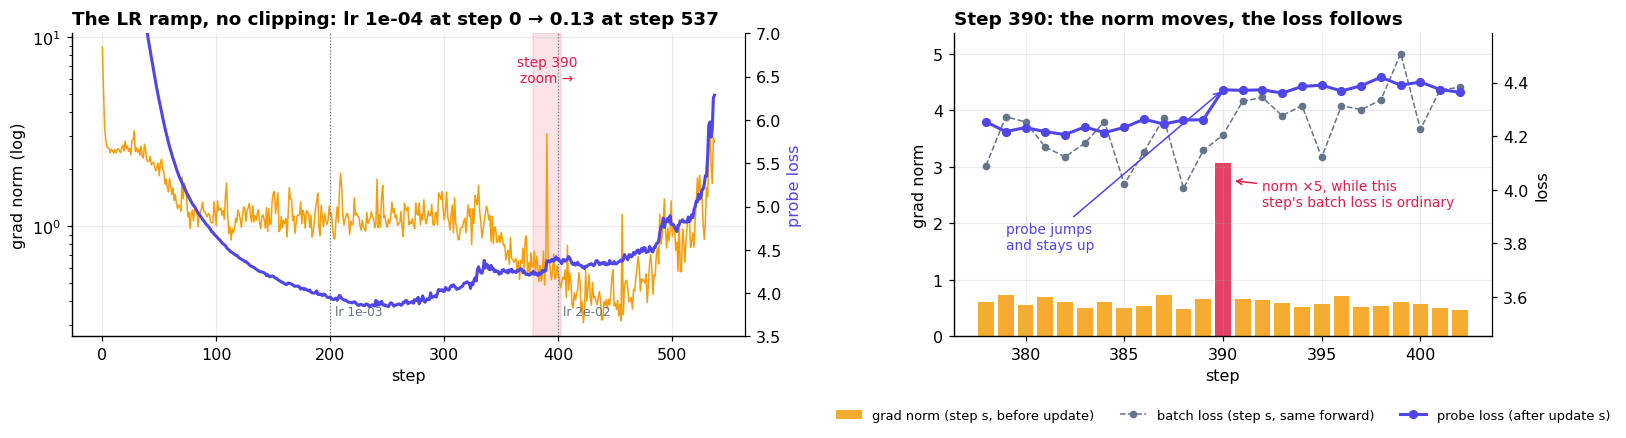

In [105]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1.25, 1]})
okr = np.arange(first_nan)
ax[0].semilogy(okr, G[okr], color=AMBER, lw=1, label='grad norm')
ax[0].set(xlabel='step', ylabel='grad norm (log)', title=f'The LR ramp, no clipping: lr {R["lr"][0]:.0e} at step 0 → {R["lr"][first_nan - 1]:.2f} at step {first_nan - 1}')
b = ax[0].twinx(); b.plot(okr, P[okr], color=INK, lw=2, label='probe loss (fixed batch)'); b.set_ylabel('probe loss', color=INK)
b.set_ylim(3.5, 7); b.grid(False); b.spines['right'].set_visible(True)
ax[0].axvspan(S - 12, S + 12, color=ROSE, alpha=0.12); ax[0].text(S, ax[0].get_ylim()[1] * 0.55, f'step {S}\nzoom →', color=ROSE, ha='center', fontsize=9)
for s_, lr_txt in ((200, f'lr {R["lr"][200]:.0e}'), (400, f'lr {R["lr"][400]:.0e}')):
    ax[0].axvline(s_, color=SLATE, lw=0.8, ls=':'); ax[0].text(s_ + 4, ax[0].get_ylim()[0] * 1.3, lr_txt, color=SLATE, fontsize=8)
w = np.arange(S - 12, S + 13)
ax[1].bar(w, G[w], color=[ROSE if i == S else AMBER for i in w], alpha=0.85, width=0.8, label='grad norm (step s, before update)')
ax[1].set(xlabel='step', ylabel='grad norm', title=f'Step {S}: the norm moves, the loss follows', ylim=(0, G[S] * 1.75))
c = ax[1].twinx()
c.plot(w, Lb[w], 'o--', color=SLATE, ms=4, lw=1, label='batch loss (step s, same forward)')
c.plot(w, P[w], 'o-', color=INK, ms=5, lw=2, label='probe loss (after update s)')
lo, hi = min(Lb[w].min(), P[w].min()), max(Lb[w].max(), P[w].max())
c.set_ylim(lo - 1.1 * (hi - lo), hi + 0.15 * (hi - lo))      # losses in the upper band, bars in the lower band
c.set_ylabel('loss'); c.grid(False); c.spines['right'].set_visible(True)
ax[1].annotate(f'norm ×{G[S] / trailing_median(G, S):.0f}, while this\nstep\'s batch loss is ordinary', xy=(S + 0.45, G[S] * 0.9),
               xytext=(S + 2, G[S] * 0.75), color=ROSE, fontsize=9, arrowprops=dict(arrowstyle='->', color=ROSE))
c.annotate('probe jumps\nand stays up', xy=(S, P[S]), xytext=(S - 11, lo - 0.45 * (hi - lo)), color=INK, fontsize=9,
           arrowprops=dict(arrowstyle='->', color=INK))
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = c.get_legend_handles_labels()
c.legend(h1 + h2, l1 + l2, fontsize=8.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

**What happened.**

* **Normal run.** After warmup the norm sits between 0.9 and 1.04 (median 0.948, p99 1.11). Clipping at 1.0 touches 13% of steps
  and only shaves them. The few isolated spikes (1.37–1.45 at steps 101, 109, 295, 414, 1046) get capped to norm 1.0 by clipping.
  This distribution is what V5 should pick its clip threshold from, as the lecture says: data, not habit.
* **Step 390 of the ramp** (lr ≈ 0.018): the grad norm jumps **0.67 → 3.06, 5× its trailing median**. The batch loss from that
  *same* forward pass is 4.204, an ordinary value (z = +0.6 against the previous 20 steps). Nothing in the loss says anything is
  wrong. The update made from that gradient lifts the fixed probe loss **4.262 → 4.373**, 5.7× its normal step-to-step jitter, and
  it **stays there** for every following step. The norm moved at step *s*. The loss only showed it at *s + 1* and never recovered.
* **The wider picture (left panel).** The probe loss bottoms out at step 251 (3.845, lr ≈ 2.9×10⁻³). Between steps 300 and 450 the
  median grad norm *falls* (1.06 → 0.42) while the probe loss quietly climbs (4.17 → 4.35), so a falling norm is not good news
  either. What matters is the norm's *shape*. From step ~460 it climbs steadily (0.46 → 2.3), about 80 steps before NaN at step 538.
* Clipping at 1.0 would have scaled step 390's gradient to a third before it reached AdamW. That is the guard from the lecture,
  and the norm is the number that tells you it fired.

## 5 · MFU, measured honestly

Model FLOPs Utilisation divides the arithmetic the model *needed* by what the chip *could* have done in the same
time. The numerator uses 6N per token (2N forward, 4N backward) plus the attention-score term 12·L·T·C, which
6N leaves out. N counts every weight that takes part in a matmul, so the tied `wte` counts once (it is the head),
and the position table does not (it is a lookup).

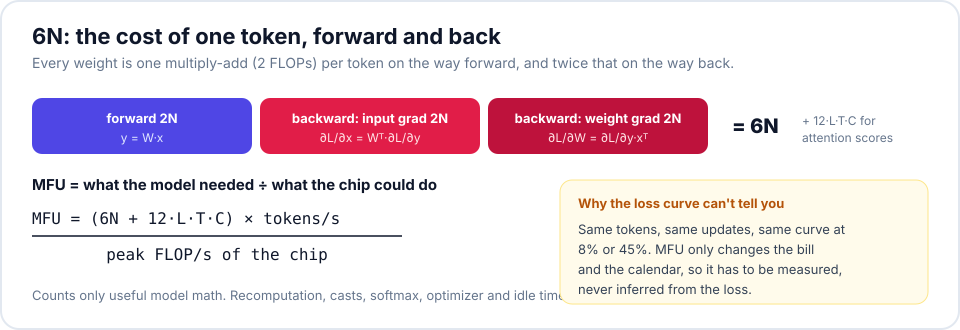

In [21]:
figure('04-mfu.svg')

In [22]:
N = n_params(main_model, exclude_pos=True)
L_, C_ = Cfg.n_layer, Cfg.n_embd
flops_tok = 6 * N + 12 * L_ * MAIN_T * C_
dt = np.median(MAIN['dt'][100:])
tps = MAIN_B * MAIN_T / dt
PEAK = 65e12          # T4 datasheet: 65 TFLOP/s dense fp16 on tensor cores

def bench_mm(n=4096, it=30, dt_=torch.float16):
    a = torch.randn(n, n, device=dev, dtype=dt_); b_ = torch.randn(n, n, device=dev, dtype=dt_)
    for _ in range(3): a @ b_
    sync(); t = time.perf_counter()
    for _ in range(it): a @ b_
    sync(); return 2 * n ** 3 * it / (time.perf_counter() - t)
ach_mm = max(bench_mm(n) for n in (2048, 4096, 8192))
mfu = flops_tok * tps / PEAK
mfu_rows = [('N (matmul weights)', f'{N:,}'), ('FLOPs per token = 6N + 12·L·T·C', f'{flops_tok / 1e6:.1f} M  (attention adds {12 * L_ * MAIN_T * C_ / (6 * N) * 100:.1f}%)'),
            ('median step time (after warmup)', f'{dt * 1e3:.1f} ms'), ('tokens per second', f'{tps:,.0f}'),
            ('model FLOP/s achieved', f'{flops_tok * tps / 1e12:.2f} TFLOP/s'), ('T4 peak, fp16 tensor cores', f'{PEAK / 1e12:.0f} TFLOP/s'),
            ('**MFU**', f'**{100 * mfu:.1f}%**'), ('best fp16 matmul this T4 actually reaches', f'{ach_mm / 1e12:.1f} TFLOP/s = {100 * ach_mm / PEAK:.0f}% of peak'),
            ('MFU relative to that measured ceiling', f'{100 * flops_tok * tps / ach_mm:.0f}%')]
display(pd.DataFrame(mfu_rows, columns=['quantity', 'value']).set_index('quantity'))

,value
quantity,
N (matmul weights),"29,964,288"
FLOPs per token = 6N + 12·L·T·C,186.9 M (attention adds 3.9%)
median step time (after warmup),92.1 ms
tokens per second,"44,470"
model FLOP/s achieved,8.31 TFLOP/s
"T4 peak, fp16 tensor cores",65 TFLOP/s
**MFU**,**12.8%**
best fp16 matmul this T4 actually reaches,21.2 TFLOP/s = 33% of peak
MFU relative to that measured ceiling,39%


**Where the time goes.** A CUDA profile of five training steps, with every kernel sorted into what it is doing.
Only the first bar is the work that MFU counts.

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


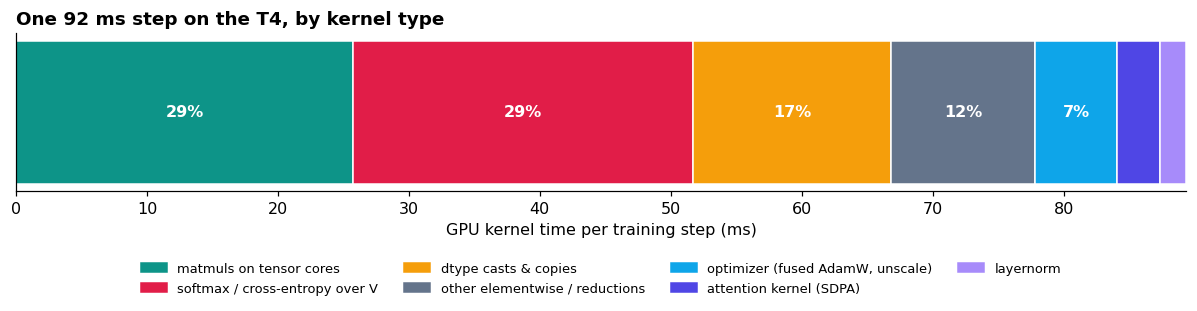

,ms / step,share
softmax / cross-entropy over V,25.99,29.1%
matmuls on tensor cores,25.73,28.8%
dtype casts & copies,15.14,16.9%
other elementwise / reductions,10.98,12.3%
"optimizer (fused AdamW, unscale)",6.24,7.0%
attention kernel (SDPA),3.26,3.6%
layernorm,2.04,2.3%


,ms / step,tokens / s,MFU
variant,,,
"eager, B=16 (the run above)",91.6,"44,704",12.9%
"eager, B=32",178.2,"45,959",13.2%
"torch.compile, B=16",89.4,"45,798",13.2%
"torch.compile, B=32",173.5,"47,209",13.6%


compile took 4s | peak memory 7.1 GB of 16 GB


In [23]:
from torch.profiler import profile, ProfilerActivity

def one_step(m, o, sc, B=MAIN_B):
    x, y = get_batch('train', B, MAIN_T)
    with autocast(): loss = F.cross_entropy(m(x).float().view(-1, V), y.view(-1))
    sc.scale(loss).backward(); sc.unscale_(o)
    torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
    sc.step(o); sc.update(); o.zero_grad(set_to_none=True)
    return loss.item()

def time_steps(m, o, sc, B=MAIN_B, n=20):
    for _ in range(5): one_step(m, o, sc, B)
    sync(); t = time.perf_counter()
    for _ in range(n): one_step(m, o, sc, B)
    sync(); return (time.perf_counter() - t) / n

prof_breakdown = None
if dev == 'cuda':
    torch.manual_seed(0); pm = GPT(Cfg()).to(dev); po = make_opt(pm, 3e-4); ps = torch.amp.GradScaler(enabled=(AMP == torch.float16))
    for _ in range(3): one_step(pm, po, ps)
    with profile(activities=[ProfilerActivity.CUDA]) as prof:
        for _ in range(5): one_step(pm, po, ps)
        sync()
    def bucket(k):
        k = k.lower()
        if 'fmha' in k or 'attention' in k or 'flash' in k: return 'attention kernel (SDPA)'
        if 'gemm' in k or 'cutlass' in k or 's1688' in k or 'xmma' in k: return 'matmuls on tensor cores'
        if 'softmax' in k or 'nll' in k or 'log_softmax' in k: return 'softmax / cross-entropy over V'
        if 'copy' in k or 'float16_copy' in k or 'to_copy' in k: return 'dtype casts & copies'
        if 'multi_tensor' in k or 'adam' in k: return 'optimizer (fused AdamW, unscale)'
        if 'layer_norm' in k: return 'layernorm'
        return 'other elementwise / reductions'
    agg = {}
    for e in prof.key_averages():
        if e.self_device_time_total > 0:
            agg[bucket(e.key)] = agg.get(bucket(e.key), 0) + e.self_device_time_total / 5 / 1e3
    prof_breakdown = pd.Series(agg).sort_values(ascending=False)
    gpu_ms = prof_breakdown.sum()
    order = ['matmuls on tensor cores'] + [k for k in prof_breakdown.index if k != 'matmuls on tensor cores']
    fig, ax = plt.subplots(figsize=(11, 3.4))
    colors = {'matmuls on tensor cores': TEAL, 'softmax / cross-entropy over V': ROSE, 'dtype casts & copies': AMBER,
              'attention kernel (SDPA)': INK, 'optimizer (fused AdamW, unscale)': SKY, 'layernorm': '#A78BFA', 'other elementwise / reductions': SLATE}
    left = 0
    for k in order:
        v = prof_breakdown[k]; ax.barh(0, v, left=left, color=colors[k], edgecolor='white')
        if v / gpu_ms > 0.045: ax.text(left + v / 2, 0, f'{100 * v / gpu_ms:.0f}%', ha='center', va='center', color='white', fontweight='bold')
        left += v
    ax.set(xlim=(0, gpu_ms), yticks=[], xlabel='GPU kernel time per training step (ms)', title=f'One {dt * 1e3:.0f} ms step on the T4, by kernel type')
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in order], labels=order, ncol=4, fontsize=8.5,
              loc='upper center', bbox_to_anchor=(0.5, -0.38)); ax.grid(False)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame({'ms / step': prof_breakdown.round(2), 'share': (100 * prof_breakdown / gpu_ms).round(1).astype(str) + '%'}))

    # Two cheap levers, measured: larger batch, and torch.compile.
    var = [('eager, B=16 (the run above)', time_steps(pm, po, ps, 16), 16), ('eager, B=32', time_steps(pm, po, ps, 32), 32)]
    cm = torch.compile(pm)
    t0 = time.time(); one_step(cm, po, ps); compile_s = time.time() - t0
    var += [('torch.compile, B=16', time_steps(cm, po, ps, 16), 16), ('torch.compile, B=32', time_steps(cm, po, ps, 32), 32)]
    display(pd.DataFrame([(n_, f'{t_ * 1e3:.1f}', f'{b_ * MAIN_T / t_:,.0f}', f'{100 * flops_tok * b_ * MAIN_T / t_ / PEAK:.1f}%') for n_, t_, b_ in var],
                         columns=['variant', 'ms / step', 'tokens / s', 'MFU']).set_index('variant'))
    print(f'compile took {compile_s:.0f}s | peak memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB')
    del pm, cm

**My MFU is 12.8%:** 8.3 TFLOP/s of model math against the T4's 65 TFLOP/s datasheet peak, at 44,470 tokens/s.
What stands between that and 40%, biggest first:

1. **The chip can't reach its own datasheet.** The fastest fp16 matmul this Colab T4 sustains is **21.2 TFLOP/s, 33% of peak**
   (a 70 W card that drops its clocks under load). So 40% against the datasheet is out of reach here even with perfect code. Against
   what the card actually delivers, this loop is at **39%**.
2. **The vocabulary eats the step.** The profile shows the matmuls MFU counts take only **29%** of GPU time. Another **29%**
   goes to softmax and cross-entropy over 50,304 classes, run in fp32 on a 4,096 × 50,304 tensor (824 MB) because I cast logits to
   `.float()` for a stable loss. A further **17%** is dtype casts, partly that same `.float()` and partly autocast re-casting every
   fp32 weight to fp16 on every forward. In a 30M model where 19M weights are the embedding, the per-token cost of the
   vocabulary is not a footnote.
3. **The model is too thin to keep tensor cores busy.** At C = 384, every matmul has a 384-wide inner dimension, so it does little
   arithmetic per byte it moves. `torch.compile` (+2.5%) and doubling the batch (+3%) barely help, which confirms the gap is
   in the work itself, not launch overhead. GPU busy time (89 ms) is 97% of the wall-clock step (92 ms).
4. **fp16 bookkeeping.** The T4 has no bf16 tensor cores, so the loop pays for loss scaling, unscaling and an inf check on every step.
   Together with fused AdamW that is 7%.

**Closing the gap**, in the order I'd try them: a chunked or fused cross-entropy that never materialises fp32 logits (attacks most
of the 46% in item 2; `[estimate]` ~1.7× faster step, about 22% MFU); a wider model (C ≥ 768) so matmuls dominate; and a
bf16-native GPU (A100/H100), where both the ceiling and the arithmetic are on our side.

## 6 · The number 0.1, in fp32, bf16 and fp8 E4M3

**By hand first.** 0.1 = 1.6 × 2⁻⁴, so every format stores sign 0 and an exponent meaning −4; they differ in the
exponent bias and in how many digits of the mantissa 1.6 they keep. 0.6 in binary never ends: double it,
take the integer part, repeat.

| step | 0.6 × 2 → | bit | | step | 0.4 × 2 → | bit |
|---|---|---|---|---|---|---|
| 1 | 1.2 | **1** | | 3 | 0.8 | **0** |
| 2 | 0.4 | **0** | | 4 | 1.6 | **1** |

…and 0.6 comes back, so the mantissa digits are `1001 1001 1001 …` forever. Each format cuts this and rounds to nearest:

| | sign | exponent | mantissa kept | first dropped bit | stored value | error |
|---|---|---|---|---|---|---|
| **fp32** (bias 127) | `0` | −4 + 127 = 123 = `01111011` | `10011001100110011001100` (23) | `1` → round up → `…1101` | 0.100000001490116 | 1.5 × 10⁻⁹ |
| **bf16** (bias 127) | `0` | 123 = `01111011` | `1001100` (7) | `1` → round up → `1001101` | 0.10009765625 | 9.8 × 10⁻⁵ |
| **fp8 E4M3** (bias 7) | `0` | −4 + 7 = 3 = `0011` | `100` (3) | `1` → round up → `101` | 0.1015625 | 1.6 × 10⁻³ |

Full words: fp32 `0 01111011 10011001100110011001101` = `0x3DCCCCCD`; bf16 `0 01111011 1001101` = `0x3DCD`;
E4M3 `0 0011 101` = `0x1D`.

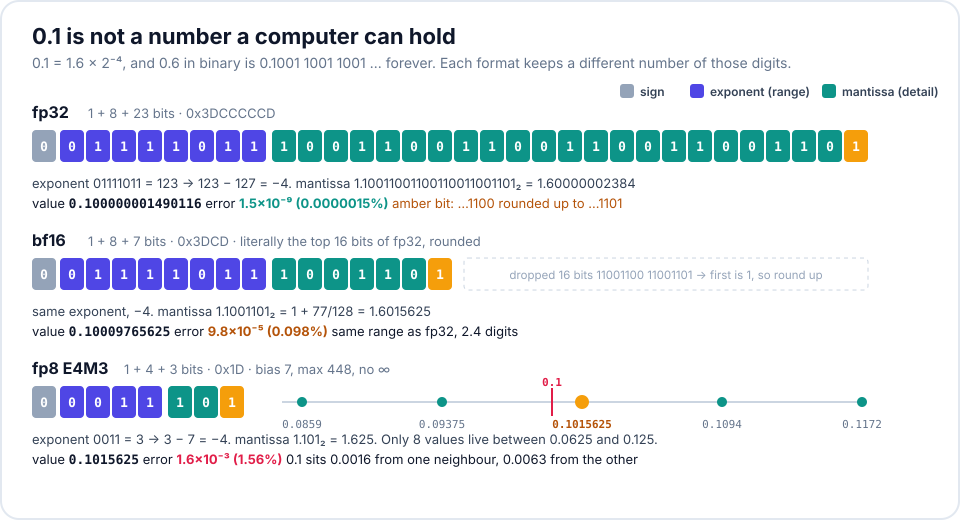

In [24]:
figure('05-point-one.svg')

**Then checked by machine.** The encoder below does the hand method (exact rational arithmetic, round to nearest even)
for any (exponent bits, mantissa bits, bias), and its bits are compared with what PyTorch and `struct` actually store.

In [25]:
def encode(x, e_bits, m_bits, bias):
    """Hand method: find the exponent, read off m_bits mantissa digits, round half to even."""
    x = Fraction(x); E = 0
    while x >= 2: x /= 2; E += 1
    while x < 1: x *= 2; E -= 1
    frac = x - 1
    scaled = frac * 2 ** m_bits
    m = int(scaled); rem = scaled - m
    if rem > Fraction(1, 2) or (rem == Fraction(1, 2) and m % 2): m += 1
    if m == 2 ** m_bits: m = 0; E += 1
    bits = '0' + format(E + bias, f'0{e_bits}b') + format(m, f'0{m_bits}b')
    value = (1 + Fraction(m, 2 ** m_bits)) * Fraction(2) ** E
    return bits, value

def machine_bits(fmt):
    if fmt == 'fp32': return format(struct.unpack('>I', struct.pack('>f', 0.1))[0], '032b')
    t = torch.tensor(0.1).to({'bf16': torch.bfloat16, 'e4m3': torch.float8_e4m3fn}[fmt])
    raw = t.view(torch.int16 if fmt == 'bf16' else torch.uint8).item() & (0xFFFF if fmt == 'bf16' else 0xFF)
    return format(raw, '016b' if fmt == 'bf16' else '08b')

rows = []
for fmt, e, m_, bias in (('fp32', 8, 23, 127), ('bf16', 8, 7, 127), ('e4m3', 4, 3, 7)):
    bits, val = encode(Fraction(1, 10), e, m_, bias)
    mb = machine_bits(fmt)
    rows.append((fmt, f'{bits[0]} {bits[1:1 + e]} {bits[1 + e:]}', hex(int(bits, 2)), mb == bits, f'{float(val):.15g}',
                 f'{float(abs(val - Fraction(1, 10))):.2e}', f'{100 * float(abs(val - Fraction(1, 10)) * 10):.5f}%'))
display(pd.DataFrame(rows, columns=['format', 'sign exponent mantissa (by hand)', 'hex', 'matches PyTorch/struct', 'stored value', 'abs error', 'rel error']).set_index('format'))

,sign exponent mantissa (by hand),hex,matches PyTorch/struct,stored value,abs error,rel error
format,,,,,,
fp32,0 01111011 10011001100110011001101,0x3dcccccd,True,0.100000001490116,1.49e-09,0.00000%
bf16,0 01111011 1001101,0x3dcd,True,0.10009765625,9.77e-05,0.09766%
e4m3,0 0011 101,0x1d,True,0.1015625,1.56e-03,1.56250%


**Why this matters in a loop.** A training step is `w ← w − lr·g`, a small number added to a larger one. If the
addend is under half the gap between neighbouring representable values, it rounds away entirely. Add 0.1 ten
thousand times (the true answer is 1000) and watch where each format stops. And the other failure, a gradient too
small to store, is the reason fp16 needs loss scaling.

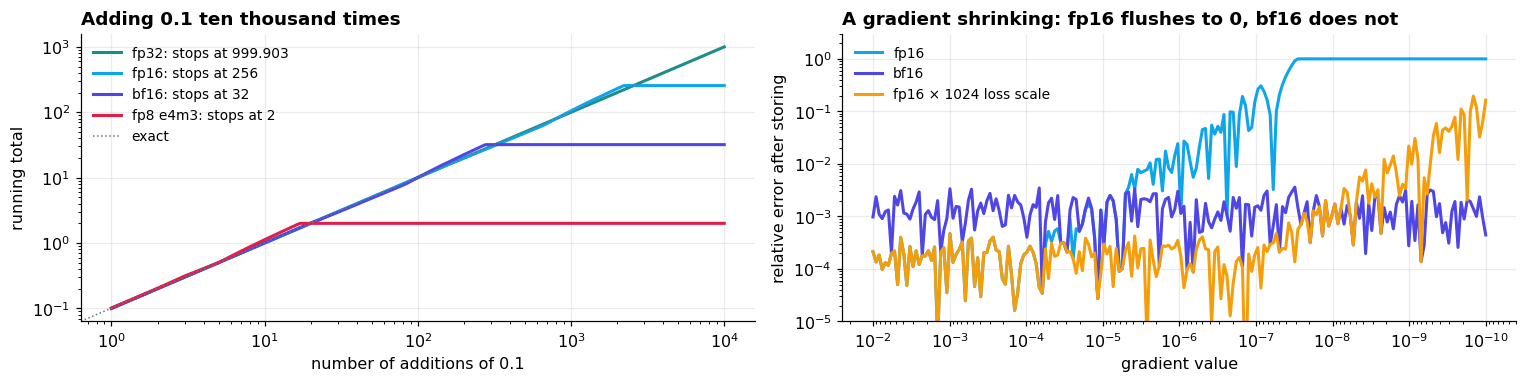

gradient 1e-04:  fp16 stores 1.000e-04   bf16 stores 1.001e-04
gradient 1e-06:  fp16 stores 1.013e-06   bf16 stores 9.984e-07
gradient 1e-08:  fp16 stores 0.000e+00   bf16 stores 1.001e-08

This notebook trained in fp16 (the T4 has no bf16 tensor cores), so GradScaler was mandatory: loss scale went 65536 → 131072, with 0 overflow-skipped steps in 2,000.


In [26]:
sums = {}
for name, dt_ in (('fp32', torch.float32), ('fp16', torch.float16), ('bf16', torch.bfloat16), ('fp8 e4m3', torch.float8_e4m3fn)):
    acc = torch.zeros((), dtype=torch.float32); step_ = torch.tensor(0.1)
    trace = []
    for i in range(10_000):
        acc = (acc + step_.to(dt_).float()).to(dt_).float()      # store the running total in the format each time
        trace.append(acc.item())
    sums[name] = np.array(trace)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for (name, tr), c in zip(sums.items(), (TEAL, SKY, INK, ROSE)):
    ax[0].plot(np.arange(1, 10_001), tr, color=c, lw=2, label=f'{name}: stops at {tr[-1]:g}')
ax[0].plot([0, 10_000], [0, 1000], color=SLATE, ls=':', lw=1, label='exact')
ax[0].set(xscale='log', yscale='log', xlabel='number of additions of 0.1', ylabel='running total', title='Adding 0.1 ten thousand times')
ax[0].legend(fontsize=9)
gvals = np.logspace(-2, -10, 200)
for name, dt_, c in (('fp16', torch.float16, SKY), ('bf16', torch.bfloat16, INK), ('fp16 × 1024 loss scale', torch.float16, AMBER)):
    s_ = 1024.0 if 'scale' in name else 1.0
    kept = (torch.tensor(gvals * s_).to(dt_).double() / s_).numpy()
    ax[1].loglog(gvals, np.abs(kept - gvals) / gvals + 1e-12, color=c, lw=2, label=name)
ax[1].set(xlabel='gradient value', ylabel='relative error after storing', title='A gradient shrinking: fp16 flushes to 0, bf16 does not', ylim=(1e-5, 3))
ax[1].invert_xaxis(); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
for g_ in (1e-4, 1e-6, 1e-8):
    print(f'gradient {g_:.0e}:  fp16 stores {torch.tensor(g_).half().item():.3e}   bf16 stores {torch.tensor(g_).bfloat16().item():.3e}')
sc_hist = MAIN['scale']
print(f'\nThis notebook trained in fp16 (the T4 has no bf16 tensor cores), so GradScaler was mandatory: loss scale went '
      f'{sc_hist[0]:.0f} → {sc_hist[-1]:.0f}, with {int((np.diff(sc_hist) < 0).sum())} overflow-skipped steps in 2,000.')

**Which one I'd train in: bf16 mixed precision.** That means bf16 for matmul inputs and activations, fp32 for master weights and AdamW state.

* **Range beats digits.** bf16 keeps fp32's 8 exponent bits. The measured case: a 10⁻⁸ gradient is stored as **0** in fp16 and
  as 1.001×10⁻⁸ in bf16. fp16 needs a loss scaler to survive, and this notebook shows the cost: it had to run `GradScaler` the whole
  time (scale 65,536 → 131,072). That is one more moving part to tune and eventually get wrong.
* **bf16's 0.1% error per value is fine for *computing* a step, but not for *storing* the weights.** Adding 0.1 ten thousand times stalls
  at **32 in bf16** (above 32 the spacing between bf16 values is 0.25, so +0.1 rounds away) and at 256 in fp16. A weight update
  `w − lr·g` is exactly that kind of tiny addition, which is why the master copy stays in fp32 (999.9) and why the bill is 16 bytes per weight.
* **fp8 E4M3 is not a storage format.** At 1.56% error, with only 8 values between 0.0625 and 0.125 and a maximum of 448, it
  needs a scale per tensor or block, and it pays off only on hardware with fp8 tensor cores (H100/Blackwell), for matmul inputs. That's the
  production recipe, which keeps the accumulators and master weights wide. It has no place on a T4, and I'd only adopt it for V5 after a
  short side-by-side run against bf16, as the lecture's open question says.

## Summary

In [27]:
summary = [
    ('§1 shapes', 'logits B×T×V', f'16 × 256 × 50,304; logits.grad matches (softmax − onehot)/BT'),
    ('§2 gradient by hand', 'float64 relative error, 5 weights', f'{min(r[-1] for r in out):.0e} – {max(r[-1] for r in out):.0e}'),
    ('§2 gradient by hand', 'best fp32 / AMP relative error', ' / '.join(f'{e.min():.0e}' for e in curves.values())),
    ('§3 accumulation', 'gradient error vs one big batch: correct / broken', f'{res[0][1]:.1e} / {res[1][1]:.2f}'),
    ('§3 accumulation', 'avg-of-averages vs true loss (last 100 steps)', f'{gap[last].mean():+.1f}%'),
    ('§3 accumulation', 'held-out loss pos≥16: correct / broken', f'{C["val_long"][-1]:.3f} / {Bk["val_long"][-1]:.3f}'),
    ('§4 grad norm', 'step where norm moved first', f'step {S}: {G[S] / trailing_median(G, S):.1f}× median, batch loss z {trailing_z(Lb, S):+.2f}, probe +{P[S:S + 3].max() - P[S - 1]:.3f}'),
    ('§5 MFU', 'measured, vs 65 TFLOP/s T4 peak', f'{100 * mfu:.1f}% ({flops_tok * tps / 1e12:.2f} TFLOP/s, {tps:,.0f} tok/s)'),
    ('§6 0.1', 'fp32 / bf16 / E4M3', '0x3DCCCCCD / 0x3DCD / 0x1D'),
]
display(pd.DataFrame(summary, columns=['section', 'measurement', 'result']).set_index(['section', 'measurement']))

result
section             measurement                                                                                                    
§1 shapes           logits B×T×V                                       16 × 256 × 50,304; logits.grad matches (softmax − onehot)/BT
§2 gradient by hand float64 relative error, 5 weights                                                                 7e-10 – 3e-08
                    best fp32 / AMP relative error                                                                    5e-04 / 3e-03
§3 accumulation     gradient error vs one big batch: correct / broken                                                7.7e-07 / 0.48
                    avg-of-averages vs true loss (last 100 steps)                                                            -16.2%
                    held-out loss pos≥16: correct / broken                                                            2.971 / 3.249
§4 grad norm        step where norm moved first                             step 390: 5.0× median, batch loss z +0.62, probe +0.111
§5 MFU              measured, vs 65 TFLOP/s T4 peak                                              12.8% (8.31 TFLOP/s, 44,470 tok/s)
§6 0.1              fp32 / bf16 / E4M3                                                                   0x3DCCCCCD / 0x3DCD / 0x1D